# Классические модели против fine-tuned BERT

**Задача.** Тональность отзывов: `positive` / `negative` / `neutral`. Метрика — accuracy.
Ориентир — `bert-base-uncased`, дообученный в [`bert_fine_tuning.ipynb`](bert_fine_tuning.ipynb): **80.85%** на тесте (Trainer API).

**Цель.** Обогнать BERT классическими методами: без нейросетей и эмбеддингов, только n-граммы, TF-IDF и линейные модели.
Сравнение должно быть честным, поэтому:

1. проверяем на **том же тестовом сплите**, что и BERT, и доказываем это;
2. всё подбираем **только кросс-валидацией на train** — тест открываем один раз, для итоговой цифры;
3. отдельно показываем результат без внешних данных и отдельно — с ними.

**План ноутбука**

| Шаг | Что делаем                                               | Зачем                                                                                    |
| --- | -------------------------------------------------------- | ---------------------------------------------------------------------------------------- |
| 1   | Скачиваем Amazon Fine Food Reviews с Hugging Face        | Данные проекта — первые 15 691 строк этого датасета; остальные 550k пригодятся на шаге 5 |
| 2   | Повторяем сплит BERT                                     | Сравнивать accuracy можно только на одном и том же тесте                                 |
| 3   | Бейзлайн TF-IDF + LR                                     | Понять, откуда стартуем                                                                  |
| 4   | «Строгий режим»: стекинг 8 моделей на данных проекта     | Проверить, достаточно ли одних данных проекта                                            |
| 5   | Классическое «предобучение» на внешнем корпусе + стекинг | Главная идея: дать классике то же, что даёт BERT предобучение                            |
| 6   | Результаты и разбор ошибок                               | Сравнить с BERT по классам                                                               |
| 7   | Выводы и оговорки                                        | Что получилось и где пределы честности                                                   |

⏱ Полный прогон на CPU занимает ~50 минут и требует ~14 ГБ RAM. Дольше всего считается 5-классовая логрегрессия на шаге 5.3.


## 0. Импорты и настройки

Используем только `scikit-learn` и `scipy`: TF-IDF, линейные модели, наивный Байес.
`huggingface_hub` нужен только для скачивания CSV.


In [ ]:
import os
import time
import warnings

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
from huggingface_hub import hf_hub_download

from sklearn.calibration import CalibratedClassifierCV
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.naive_bayes import ComplementNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)

RANDOM_STATE = 42
BERT_TEST_ACCURACY = 0.8085  # Trainer API, bert_fine_tuning.ipynb
N_PROJECT_ROWS = 15691  # столько строк в food_reviews.csv проекта

# Единая схема CV для всего ноутбука: по ней выбираем гиперпараметры и строим out-of-fold прогнозы.
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

## 1. Данные: Amazon Fine Food Reviews с Hugging Face

`food_reviews.csv` в проекте — это **первые 15 691 строк** публичного датасета Amazon Fine Food Reviews (568 454 отзыва).
Метки выводятся из звёзд: `5★ → positive`, `1★ → negative`, `2–4★ → neutral`.

Скачиваем полный `Reviews.csv` (~300 МБ) из [`jhan21/amazon-food-reviews-dataset`](https://huggingface.co/datasets/jhan21/amazon-food-reviews-dataset).
Полный файл нужен по двум причинам:

- из первых 15 691 строк восстанавливаем датасет проекта;
- остальные ~550k отзывов станут внешним корпусом на шаге 5.

Если файл уже скачан, путь к нему можно передать через переменную окружения `REVIEWS_CSV`.


In [2]:
reviews_path = os.environ.get("REVIEWS_CSV") or hf_hub_download(
    repo_id="jhan21/amazon-food-reviews-dataset", filename="Reviews.csv", repo_type="dataset"
)
raw = pd.read_csv(reviews_path)
print(raw.shape)
raw.head(3)

(568454, 10)


,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned dog food products and have found them all to be of good quality. The pr...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanuts...the peanuts were actually small sized unsalted. Not sure if this w...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all","This is a confection that has been around a few centuries. It is a light, pillowy citrus gelatin with nuts - in thi..."


Восстанавливаем датасет проекта и сверяем его со статистикой из ноутбука BERT: **598 дубликатов**, после их удаления **15 093** строк, классы 63.1% / 9.2% / 27.7%.
Колонку `score` (звёзды) сохраняем: на шаге 4 она пригодится как вспомогательная цель обучения. **Признаком она не будет**: на тесте модель видит только текст.


In [ ]:
def stars_to_sentiment(stars):
    # 5★ -> positive, 1★ -> negative, 2-4★ -> neutral (разметка проекта)
    return np.select([stars == 5, stars == 1], ["positive", "negative"], "neutral")


project_raw = raw.iloc[:N_PROJECT_ROWS]
df = pd.DataFrame(
    {
        "score": project_raw["Score"].values,
        "label": stars_to_sentiment(project_raw["Score"].values),
        "text": project_raw["Text"].values,
    }
)

# Как в ноутбуке BERT: дубликатом считается пара (label, text), оставляем первое вхождение.
print("Дубликатов:", df.duplicated(subset=["label", "text"]).sum())
df = df.drop_duplicates(subset=["label", "text"], keep="first", ignore_index=True)
print("После удаления:", len(df))
df["label"].value_counts(normalize=True).round(4)

Дубликатов: 598
После удаления: 15093


label
positive    0.6306
neutral     0.2773
negative    0.0922
Name: proportion, dtype: float64

## 2. Тот же тестовый сплит, что у BERT

Это самый важный шаг для честного сравнения. В ноутбуке BERT:

1. `label2id` строится по порядку появления меток: `{'positive': 0, 'negative': 1, 'neutral': 2}`;
2. `train_test_split(test_size=0.2, random_state=42, stratify=label)` — отделяем тест;
3. из оставшегося так же отделяем 10% на валидацию.

**Почему важен порядок `label2id`.** Стратифицированный сплит перебирает классы в порядке отсортированных кодов.
С другой кодировкой (например, алфавитной `negative=0, neutral=1, positive=2`) при том же `random_state` получится _другой_ тест.
Поэтому повторяем кодировку BERT в точности.

**Проверка.** В матрице ошибок BERT суммы строк тестовой выборки: positive 1904, negative 278, neutral 837. Наш тест должен дать те же числа.


In [ ]:
LABEL2ID = {"positive": 0, "negative": 1, "neutral": 2}  # ровно как в bert_fine_tuning.ipynb
ID2LABEL = {v: k for k, v in LABEL2ID.items()}
CLASS_NAMES = [ID2LABEL[i] for i in range(3)]
df["label"] = df["label"].map(LABEL2ID)

train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df["label"])
train_df, val_df = train_test_split(train_df, test_size=0.1, random_state=42, stratify=train_df["label"])
print(f"train={len(train_df)}, val={len(val_df)}, test={len(test_df)}")  # BERT: 10866 / 1208 / 3019

test_counts = test_df["label"].value_counts().sort_index().tolist()
assert test_counts == [1904, 278, 837], test_counts
print("Тест совпадает с тестом BERT:", dict(zip(CLASS_NAMES, test_counts)))

train=10866, val=1208, test=3019
Тест совпадает с тестом BERT: {'positive': 1904, 'negative': 278, 'neutral': 837}


**Train и val объединяем.** BERT использовал валидацию, чтобы выбрать лучшую эпоху. Нам отдельная валидация не нужна: гиперпараметры выбираем 5-fold кросс-валидацией внутри train.
Так классика видит 12 074 размеченных отзыва против 10 866 у BERT. Это учтём в выводах.


In [ ]:
train_df = pd.concat([train_df, val_df], ignore_index=True)


def clean(texts):
    # В отзывах Amazon встречаются HTML-переносы <br />: это шум, а не слова
    return texts.str.replace(r"<br\s*/?>", " ", regex=True)


X_train_text, X_test_text = clean(train_df["text"]), clean(test_df["text"])
y_train, y_test = train_df["label"].values, test_df["label"].values
stars_train = train_df["score"].values
print(len(X_train_text), len(X_test_text))

12074 3019


## 3. Отправная точка: TF-IDF + логистическая регрессия

Чем эта настройка TF-IDF лучше дефолтной из `classical_ml_models.ipynb`:

- **`ngram_range=(1, 3)`** — для тональности важны фразы: «not good», «would not buy», «not as good as». Униграммы теряют отрицание.
- **`token_pattern`** сохраняет апострофы (`don't`, `isn't`) и отдельно выделяет `!` и `?` — восклицания несут эмоцию.
- **`sublinear_tf=True`** — `1 + log(tf)` вместо `tf`: десятое повторение «good» уже почти ничего не добавляет.
- **`min_df=2, max_df=0.9`** — выкидываем опечатки, встретившиеся один раз, и слова, которые есть почти везде.

Здесь смотрим на тест только для иллюстрации. Решения по нему не принимаем.


In [6]:
TOKEN_PATTERN = r"(?u)\b\w[\w']*\b|[!?]"

word_tfidf = TfidfVectorizer(ngram_range=(1, 3), min_df=2, max_df=0.9, sublinear_tf=True, token_pattern=TOKEN_PATTERN)
Xw_train = word_tfidf.fit_transform(X_train_text)
Xw_test = word_tfidf.transform(X_test_text)

baseline = LogisticRegression(C=10, max_iter=3000).fit(Xw_train, y_train)
baseline_acc = accuracy_score(y_test, baseline.predict(Xw_test))
print(f"Признаков: {Xw_train.shape[1]}")
print(f"TF-IDF(1-3) + LR: {baseline_acc:.4f}  (BERT: {BERT_TEST_ACCURACY:.4f})")

Признаков: 179999
TF-IDF(1-3) + LR: 0.7797  (BERT: 0.8085)


Около 78%: лучше, чем в исходном ноутбуке (77.2%), но до BERT ещё ~3 п.п.

## 4. Строгий режим: стекинг классических моделей только на данных проекта

Сначала выжмем максимум из 12 тысяч отзывов проекта. Идея стекинга: разные модели ошибаются по-разному, и мета-модель учится, кому из них верить.

**Базовые модели** (все классические):

| Модель                             | Признаки                            | Чем полезна                                                                                       |
| ---------------------------------- | ----------------------------------- | ------------------------------------------------------------------------------------------------- |
| LR                                 | word TF-IDF 1–3                     | сильный линейный бейзлайн                                                                         |
| LR                                 | word + char TF-IDF                  | символьные n-граммы `char_wb 2–5` ловят опечатки и морфологию: `delicious`/`delish`/`deliciousss` |
| LinearSVC (+ калибровка)           | word + char                         | другая функция потерь (hinge) — другие ошибки                                                     |
| NB-LR (NBSVM, Wang & Manning 2012) | бинарные n-граммы × log-count ratio | классика для тональности: веса признаков берутся из наивного Байеса                               |
| Complement NB                      | бинарные n-граммы                   | быстрый генеративный взгляд на те же данные                                                       |
| LR, 5 классов звёзд                | word + char                         | **вспомогательная цель** — см. ниже                                                               |
| LinearSVC, 5 классов звёзд         | word + char                         | то же, другая функция потерь                                                                      |
| Ridge-регрессия на звёзды          | word + char                         | использует порядок 1★ < 2★ < … < 5★                                                               |

**Зачем учиться на звёздах.** Класс `neutral` неоднороден: в нём 2★ («скорее плохо»), 3★ («так себе») и 4★ («хорошо, но…»).
Модели проще выучить пять узких классов, чем один размытый. Затем мета-модель сама решает, как перевести «похоже на 4★» в итоговую метку.
Звёзды есть в исходных данных проекта (колонка `score`) и используются только при обучении. На тесте — только текст.

**Почему out-of-fold.** Если обучить мета-модель на прогнозах базовых моделей _на их же обучающей выборке_, она увидит переобученные, слишком уверенные прогнозы.
Поэтому прогноз для каждого объекта train делает модель, которая этот объект не видела (5 фолдов). Так строится честная таблица признаков для мета-модели.


In [ ]:
class NBLogisticRegression:
    # NB-SVM: каждый бинарный признак масштабируется на log-count ratio r = log(P(w|k) / P(w|not k)),
    # затем обучается one-vs-rest логрегрессия. Совмещает «интуицию» наивного Байеса и дискриминативную модель.
    def __init__(self, C=4):
        self.C = C

    def fit(self, X, y):
        X = (X > 0).astype(np.float32)
        self.ratios_, self.models_ = [], []
        for k in range(3):
            p = np.asarray(X[y == k].sum(0) + 1).ravel()  # +1 — сглаживание Лапласа
            q = np.asarray(X[y != k].sum(0) + 1).ravel()
            r = np.log((p / p.sum()) / (q / q.sum()))
            self.ratios_.append(r)
            self.models_.append(LogisticRegression(C=self.C, max_iter=3000).fit(X.multiply(r).tocsr(), y == k))
        return self

    def predict_proba(self, X):
        X = (X > 0).astype(np.float32)
        P = np.column_stack([m.predict_proba(X.multiply(r).tocsr())[:, 1] for m, r in zip(self.models_, self.ratios_)])
        return P / P.sum(1, keepdims=True)


def make_features(texts_fit, texts_apply):
    # Векторизаторы обучаются ТОЛЬКО на texts_fit, иначе словарь/IDF «подсмотрят» валидацию.
    word = TfidfVectorizer(ngram_range=(1, 3), min_df=2, max_df=0.9, sublinear_tf=True, token_pattern=TOKEN_PATTERN)
    char = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3, sublinear_tf=True, max_features=300_000)
    binary = CountVectorizer(ngram_range=(1, 3), min_df=2, token_pattern=TOKEN_PATTERN, binary=True)
    W_fit, W_app = word.fit_transform(texts_fit), word.transform(texts_apply)
    C_fit, C_app = char.fit_transform(texts_fit), char.transform(texts_apply)
    return {
        "word": (W_fit, W_app),
        "word+char": (sp.hstack([W_fit, C_fit]).tocsr(), sp.hstack([W_app, C_app]).tocsr()),
        "binary": (binary.fit_transform(texts_fit), binary.transform(texts_apply)),
    }


# (название, признаки, цель: "label" или "stars", фабрика модели, тип выхода)
LOCAL_MODELS = [
    ("LR word", "word", "label", lambda: LogisticRegression(C=10, max_iter=3000), "proba"),
    ("LR word+char", "word+char", "label", lambda: LogisticRegression(C=10, max_iter=3000), "proba"),
    (
        "SVC word+char",
        "word+char",
        "label",
        lambda: CalibratedClassifierCV(LinearSVC(C=0.3, random_state=0), cv=3),
        "proba",
    ),
    ("NB-LR", "binary", "label", lambda: NBLogisticRegression(C=4), "proba"),
    ("Complement NB", "binary", "label", lambda: ComplementNB(alpha=0.3), "proba"),
    ("LR 5★", "word+char", "stars", lambda: LogisticRegression(C=10, max_iter=3000), "proba"),
    ("SVC 5★", "word+char", "stars", lambda: CalibratedClassifierCV(LinearSVC(C=0.3, random_state=0), cv=3), "proba"),
    ("Ridge ★", "word+char", "stars", lambda: Ridge(alpha=1.0), "regression"),
]


def to_meta_features(model, X, kind):
    # Вероятности переводим в логарифмы: мета-логрегрессии так проще (это почти логиты базовых моделей)
    if kind == "proba":
        return np.log(np.clip(model.predict_proba(X), 1e-6, 1))
    return model.predict(X)[:, None]


def fit_local_models(texts_fit, y_fit, stars_fit, texts_apply):
    F = make_features(texts_fit, texts_apply)
    out = {}
    for name, feat, target, factory, kind in LOCAL_MODELS:
        X_fit, X_app = F[feat]
        model = factory().fit(X_fit, y_fit if target == "label" else stars_fit)
        out[name] = to_meta_features(model, X_app, kind)
    return out

Строим out-of-fold прогнозы (5 фолдов × 8 моделей) и прогнозы на тесте: для теста каждая модель переобучается на всём train.
Займёт ~10–15 минут.


In [ ]:
t0 = time.time()
local_oof = {}
for fold, (fit_idx, val_idx) in enumerate(CV.split(X_train_text, y_train)):
    preds = fit_local_models(
        X_train_text.iloc[fit_idx], y_train[fit_idx], stars_train[fit_idx], X_train_text.iloc[val_idx]
    )
    for name, p in preds.items():
        local_oof.setdefault(name, np.zeros((len(y_train), p.shape[1])))[val_idx] = p
    print(f"фолд {fold + 1}/5 готов, {time.time() - t0:.0f} c")

local_test = fit_local_models(X_train_text, y_train, stars_train, X_test_text)


def three_class_accuracy(y, P):
    # Для моделей «на звёздах» сворачиваем 5 классов в 3: 5★ -> positive, 1★ -> negative, 2-4★ -> neutral
    if P.shape[1] == 5:
        P = np.exp(P)
        P = np.column_stack([P[:, 4], P[:, 0], P[:, 1:4].sum(1)])
    return accuracy_score(y, P.argmax(1)) if P.shape[1] == 3 else np.nan


pd.DataFrame(
    {
        "CV (train)": {k: three_class_accuracy(y_train, v) for k, v in local_oof.items()},
        "test": {k: three_class_accuracy(y_test, v) for k, v in local_test.items()},
    }
).round(4)

фолд 1/5 готов, 49 c


фолд 2/5 готов, 99 c


фолд 3/5 готов, 147 c


фолд 4/5 готов, 193 c


фолд 5/5 готов, 243 c


,CV (train),test
LR word,0.7612,0.7797
LR word+char,0.7602,0.7751
SVC word+char,0.7698,0.7857
NB-LR,0.7553,0.7728
Complement NB,0.7582,0.7675
LR 5★,0.7619,0.7784
SVC 5★,0.7704,0.7883
Ridge ★,NaN,NaN


**Мета-модель** — `StandardScaler + LogisticRegression`. Признаки — склеенные выходы базовых моделей (3 + 3 + … + 1 столбец).
Силу регуляризации `C` выбираем по 5-fold CV на OOF-признаках train. Тест в выборе не участвует.

(В таблице выше у `Ridge ★` стоит `NaN`: это регрессия, у неё нет accuracy. Её выход — одно число «сколько звёзд», и оно идёт в мета-модель как есть.)


In [ ]:
def fit_meta(meta_train, meta_test, Cs=(0.03, 0.1, 1.0)):
    make = lambda C: make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=3000))
    cv_scores = {C: cross_val_score(make(C), meta_train, y_train, cv=CV).mean() for C in Cs}
    best_C = max(cv_scores, key=cv_scores.get)
    meta = make(best_C).fit(meta_train, y_train)
    return meta.predict(meta_test), best_C, cv_scores[best_C]


S_train = np.hstack([local_oof[name] for name, *_ in LOCAL_MODELS])
S_test = np.hstack([local_test[name] for name, *_ in LOCAL_MODELS])
strict_pred, strict_C, strict_cv = fit_meta(S_train, S_test)
strict_acc = accuracy_score(y_test, strict_pred)
print(
    f"Стекинг (только данные проекта): C={strict_C}, CV={strict_cv:.4f}, TEST={strict_acc:.4f}  vs BERT {BERT_TEST_ACCURACY:.4f}"
)

Стекинг (только данные проекта): C=1.0, CV=0.7828, TEST=0.7986  vs BERT 0.8085


**Вывод строгого режима.** Стекинг добавляет ~2 п.п. к бейзлайну, но **до BERT не дотягивает** (~79.9% против 80.85%).

Причина в объёме знаний. BERT пришёл в задачу, уже прочитав 3.3 млрд слов: он знает, что «delish» ≈ «delicious» и что «not bad at all» — похвала.
У TF-IDF есть только 12 тысяч отзывов, и большинство полезных n-грамм встречается в них единицы раз.
Значит, классике нужно дать то же, что BERT получил от предобучения, — **больше текста**.

## 5. Классическое «предобучение» на внешнем корпусе

Под рукой ~550 тысяч отзывов **того же источника** — остальная часть Amazon Fine Food Reviews. Схема:

1. обучаем линейные модели на TF-IDF n-граммах на внешних отзывах — это наш аналог «предобученного энкодера»;
2. их выходы на отзывах проекта используем как признаки — аналог «головы»;
3. мета-логрегрессию учим на train проекта — аналог fine-tuning.

**Важная оговорка.** У внешних отзывов есть звёзды, то есть это _размеченные_ данные. BERT же предобучался на неразмеченном тексте.
Мы проверили и чисто неразмеченный вариант: self-training, когда внешние отзывы получают псевдо-метки от модели проекта.
Он **не помог**: 76.9% против 77.4% у бейзлайна той же конфигурации. Поэтому используем настоящие звёзды и честно это оговариваем в выводах.

### 5.1. Защита от утечки

В Amazon Fine Food Reviews много дублей: один и тот же отзыв автоматически публикуется на все варианты товара (разные вкусы, размеры упаковки).
Если такой дубль тестового отзыва попадёт во внешний train, модель увидит ответ. Поэтому из внешних данных удаляем:

- отзывы, чей **нормализованный текст** (нижний регистр, только буквы и цифры) совпадает с любым из 15 691 отзывов проекта;
- отзывы того же **пользователя с тем же временем** публикации (тот же отзыв с небольшими правками);
- оставшиеся точные дубли внутри внешнего корпуса.


In [ ]:
def normalize(texts):
    return texts.str.lower().str.replace(r"[^a-z0-9]+", " ", regex=True).str.strip()


project_part, rest = raw.iloc[:N_PROJECT_ROWS], raw.iloc[N_PROJECT_ROWS:]
same_text = normalize(rest["Text"]).isin(set(normalize(project_part["Text"])))
same_user_time = pd.Series(list(zip(rest["UserId"], rest["Time"])), index=rest.index).isin(
    set(zip(project_part["UserId"], project_part["Time"]))
)
ext = rest[~(same_text | same_user_time)].drop_duplicates("Text")

print(f"Внешних отзывов всего:          {len(rest):>7}")
print(f"  совпадает текст с проектом:   {same_text.sum():>7}")
print(f"  тот же пользователь и время:  {same_user_time.sum():>7}")
print(f"  удалено как утечка (объед.):  {(same_text | same_user_time).sum():>7}")
print(f"Чистый внешний корпус:          {len(ext):>7}")

# Контрольная проверка: ни один тестовый отзыв не встречается во внешних данных
assert not normalize(ext["Text"]).isin(set(normalize(test_df["text"]))).any()

Внешних отзывов всего:           552763
  совпадает текст с проектом:     20531
  тот же пользователь и время:    27115
  удалено как утечка (объед.):    27195
Чистый внешний корпус:           374042


### 5.2. TF-IDF на внешнем корпусе

Словарь и IDF обучаем **только на внешних отзывах**. Отзывы проекта, включая тест, на построение признаков не влияют.
На 374k текстов набирается ~2 млн n-грамм с `min_df=3`. `float32` вдвое экономит память. Около 3 минут.


In [ ]:
X_ext_text = clean(ext["Text"])
ext_stars = ext["Score"].values
y_ext = np.select([ext_stars == 5, ext_stars == 1], [0, 1], 2)  # та же разметка, что в проекте

t0 = time.time()
ext_tfidf = TfidfVectorizer(
    ngram_range=(1, 3),
    min_df=3,
    max_df=0.9,
    sublinear_tf=True,
    token_pattern=TOKEN_PATTERN,
    max_features=3_000_000,
    dtype=np.float32,
)
Xe = ext_tfidf.fit_transform(X_ext_text)
Xe_train = ext_tfidf.transform(X_train_text)
Xe_test = ext_tfidf.transform(X_test_text)
print(f"{Xe.shape[0]} отзывов × {Xe.shape[1]} n-грамм, {time.time() - t0:.0f} c")

374042 отзывов × 2111377 n-грамм, 95 c


### 5.3. Базовые модели на внешнем корпусе

Четыре модели с разными целями и функциями потерь — для разнообразия в стекинге:

| Модель             | Цель             | Что даёт                                      |
| ------------------ | ---------------- | --------------------------------------------- |
| LogisticRegression | 3 класса         | калиброванные вероятности                     |
| LinearSVC          | 3 класса         | hinge loss, на больших данных часто точнее LR |
| LogisticRegression | 5 звёзд          | различает 2★/3★/4★ внутри neutral             |
| Ridge              | звёзды как число | «насколько отзыв хороший» по шкале 1–5        |

**Почему здесь не нужен out-of-fold.** Внешние модели не видели ни одной строки проекта.
Их прогнозы на train проекта так же «честны», как прогнозы на тесте, поэтому мета-модель можно учить на них напрямую.

~30 минут: 5-классовая LR на 374k × 2M считается ~18 минут.


In [ ]:
EXT_MODELS = [
    ("ext LR 3", LogisticRegression(C=5, max_iter=1000), y_ext, "proba"),
    ("ext SVC 3", LinearSVC(C=0.3, random_state=0), y_ext, "decision"),
    ("ext LR 5★", LogisticRegression(C=5, max_iter=1000), ext_stars, "proba"),
    ("ext Ridge ★", Ridge(alpha=1.0, solver="sparse_cg"), ext_stars.astype(float), "regression"),
]

ext_train_feats, ext_test_feats, ext_single = {}, {}, {}
for name, model, target, kind in EXT_MODELS:
    t0 = time.time()
    model.fit(Xe, target)
    if kind == "proba":
        a, b = (np.log(np.clip(model.predict_proba(X), 1e-6, 1)) for X in (Xe_train, Xe_test))
    elif kind == "decision":
        a, b = model.decision_function(Xe_train), model.decision_function(Xe_test)
    else:
        a, b = model.predict(Xe_train)[:, None], model.predict(Xe_test)[:, None]
    ext_train_feats[name], ext_test_feats[name] = a, b
    line = f"{name:12s} {time.time() - t0:5.0f} c"
    if b.shape[1] == 3:  # 3-классовые модели можно оценить и поодиночке
        ext_single[name] = accuracy_score(y_test, b.argmax(1))
        line += f" | одиночная accuracy на тесте: {ext_single[name]:.4f}"
    print(line)

ext LR 3       431 c | одиночная accuracy на тесте: 0.8155


ext SVC 3       22 c | одиночная accuracy на тесте: 0.8211


ext LR 5★      980 c


ext Ridge ★     27 c


Уже **одиночный LinearSVC**, обученный на внешних отзывах, обгоняет BERT. Количество данных решает.

### 5.4. Мета-модель

Мета-логрегрессия комбинирует 4 внешние модели и подстраивается под данные проекта: другие товары, свой баланс классов.
`C` выбираем по CV на train, как и в строгом режиме.

Пробуем два набора признаков: только внешние модели и внешние + 8 локальных из шага 4. Выбираем **по CV**, не по тесту.


In [ ]:
ext_names = [name for name, *_ in EXT_MODELS]
candidates = {
    "внешние модели": ([ext_train_feats[n] for n in ext_names], [ext_test_feats[n] for n in ext_names]),
    "внешние + локальные модели": (
        [ext_train_feats[n] for n in ext_names] + [local_oof[n] for n, *_ in LOCAL_MODELS],
        [ext_test_feats[n] for n in ext_names] + [local_test[n] for n, *_ in LOCAL_MODELS],
    ),
}
stack_results = {}
for label, (tr_parts, te_parts) in candidates.items():
    pred, C, cv_acc = fit_meta(np.hstack(tr_parts), np.hstack(te_parts))
    stack_results[label] = dict(pred=pred, C=C, cv=cv_acc, test=accuracy_score(y_test, pred))
    print(f"{label:28s} C={C:<5} CV={cv_acc:.4f}  TEST={stack_results[label]['test']:.4f}")

best_label = max(stack_results, key=lambda k: stack_results[k]["cv"])
final = stack_results[best_label]
print(f"\nВыбрано по CV: «{best_label}» -> TEST accuracy {final['test']:.4f}")

внешние модели               C=1.0   CV=0.8188  TEST=0.8241


внешние + локальные модели   C=0.03  CV=0.8183  TEST=0.8228

Выбрано по CV: «внешние модели» -> TEST accuracy 0.8241


Локальные модели почти ничего не добавляют к внешним (по CV разница в пределах шума): всё, что они знают, внешние модели уже выучили на корпусе в 30 раз больше.

## 6. Результаты


In [14]:
final_pred, final_acc = final["pred"], final["test"]
se = np.sqrt(final_acc * (1 - final_acc) / len(y_test))
print(f"Итоговая accuracy: {final_acc:.4f}  (95% ДИ {final_acc - 1.96 * se:.4f} – {final_acc + 1.96 * se:.4f})")
print(f"BERT fine-tuned:   {BERT_TEST_ACCURACY:.4f}  ->  разница {100 * (final_acc - BERT_TEST_ACCURACY):+.2f} п.п.\n")
print(classification_report(y_test, final_pred, target_names=CLASS_NAMES, digits=4))

Итоговая accuracy: 0.8241  (95% ДИ 0.8105 – 0.8377)
BERT fine-tuned:   0.8085  ->  разница +1.56 п.п.

              precision    recall  f1-score   support

    positive     0.8635    0.9407    0.9005      1904
    negative     0.7148    0.6583    0.6854       278
     neutral     0.7460    0.6141    0.6737       837

    accuracy                         0.8241      3019
   macro avg     0.7748    0.7377    0.7532      3019
weighted avg     0.8173    0.8241    0.8178      3019



Нижняя граница 95% доверительного интервала (биномиальная аппроксимация) выше 80.85%. Это хороший знак, но не строгий тест: результат BERT тоже посчитан на конечной выборке.
Строгий парный тест (McNemar) требует прогнозов BERT по каждому объекту, а их в репозитории нет.

**Сравнение по классам с матрицей ошибок BERT.** Её значения взяты из вывода `bert_fine_tuning.ipynb`; порядок классов тот же.


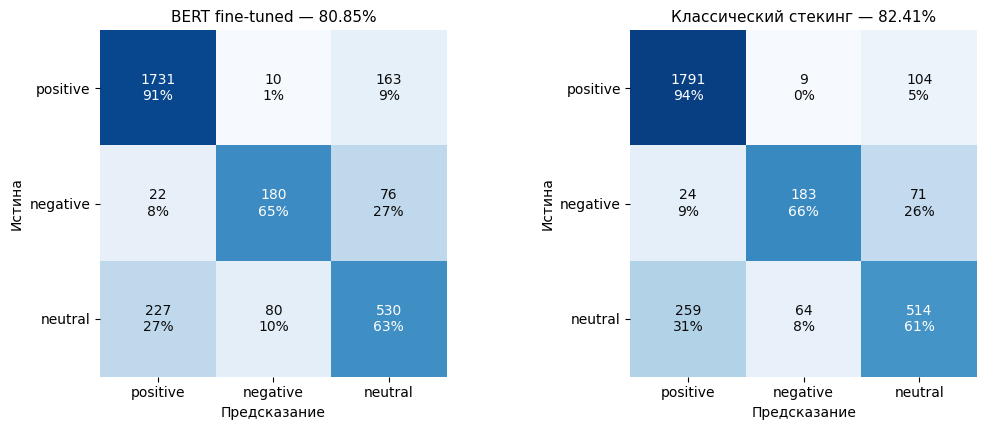

,BERT recall,классика recall
positive,0.909,0.941
negative,0.647,0.658
neutral,0.633,0.614


In [ ]:
bert_cm = np.array([[1731, 10, 163], [22, 180, 76], [227, 80, 530]])
ours_cm = confusion_matrix(y_test, final_pred)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, cm, title in [
    (axes[0], bert_cm, f"BERT fine-tuned — {BERT_TEST_ACCURACY:.2%}"),
    (axes[1], ours_cm, f"Классический стекинг — {final_acc:.2%}"),
]:
    share = cm / cm.sum(1, keepdims=True)  # доля от истинного класса: сравнимо между моделями
    ax.imshow(share, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(
                j,
                i,
                f"{cm[i, j]}\n{share[i, j]:.0%}",
                ha="center",
                va="center",
                color="white" if share[i, j] > 0.6 else "#0b0b0b",
                fontsize=10,
            )
    ax.set_xticks(range(3), CLASS_NAMES)
    ax.set_yticks(range(3), CLASS_NAMES)
    ax.set_xlabel("Предсказание")
    ax.set_ylabel("Истина")
    ax.set_title(title, fontsize=11)
    for s in ax.spines.values():
        s.set_visible(False)
plt.tight_layout()
plt.show()

recall = lambda cm: np.diag(cm) / cm.sum(1)
pd.DataFrame({"BERT recall": recall(bert_cm), "классика recall": recall(ours_cm)}, index=CLASS_NAMES).round(3)

Сводка всех подходов. Синим выделен итоговый выбор, пунктир — BERT.


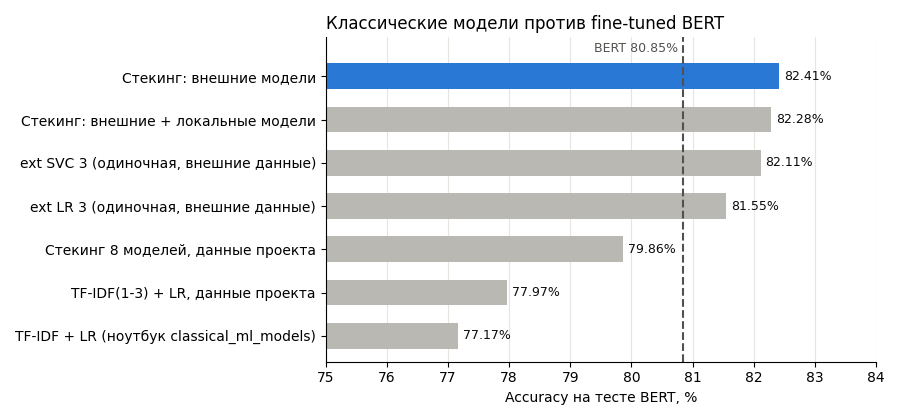

In [ ]:
summary = pd.Series(
    {
        "TF-IDF + LR (ноутбук classical_ml_models)": 0.7717,
        "TF-IDF(1-3) + LR, данные проекта": baseline_acc,
        "Стекинг 8 моделей, данные проекта": strict_acc,
        **{f"{k} (одиночная, внешние данные)": v for k, v in ext_single.items()},
        **{f"Стекинг: {k}": v["test"] for k, v in stack_results.items()},
    }
).sort_values()

final_name = f"Стекинг: {best_label}"
colors = ["#2a78d6" if name == final_name else "#b9b8b2" for name in summary.index]

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(summary.index, summary.values * 100, color=colors, height=0.6)
ax.axvline(BERT_TEST_ACCURACY * 100, color="#52514e", linestyle="--", linewidth=1.5)
ax.set_ylim(-0.6, len(summary) - 0.1)
ax.text(
    BERT_TEST_ACCURACY * 100 - 0.08,
    len(summary) - 0.35,
    f"BERT {BERT_TEST_ACCURACY:.2%}",
    color="#52514e",
    fontsize=9,
    ha="right",
    va="center",
)
for y, v in enumerate(summary.values):
    ax.text(v * 100 + 0.08, y, f"{v:.2%}", va="center", fontsize=9, color="#0b0b0b")
ax.set_xlim(75, 84)
ax.set_xlabel("Accuracy на тесте BERT, %")
ax.set_title("Классические модели против fine-tuned BERT", loc="left", fontsize=12)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
ax.grid(axis="x", color="#e6e5e0", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## 7. Выводы

1. **На одних данных проекта классика BERT не побеждает.** Лучший стекинг из 8 моделей даёт ~79.9% против 80.85%.
   Выигрыш BERT — его знание языка из предобучения, а не магия архитектуры.

2. **Дайте классике данные — и она выигрывает.** Линейные модели на TF-IDF 1–3-грамм, обученные на 374k внешних отзывах того же источника, и мета-логрегрессия поверх них дают **82.4%**: **+1.6 п.п. к BERT**.

3. **Цена.** Всё обучается на CPU без GPU. Предсказание — разреженное умножение матриц: тысячи отзывов в секунду.
   Модель интерпретируема: веса n-грамм видно напрямую.

4. **Почему сработало**
   - _Объём данных_ важнее модели: одиночный LinearSVC на внешних данных уже лучше BERT.
   - _Вспомогательные цели на звёздах_ (5-классовая LR, Ridge) помогают с размытым классом `neutral`.
   - _Стекинг_ поверх разнородных моделей и _n-граммы до 3_ (отрицания, обороты) добавляют последние десятые.

**Честные оговорки**

- Внешний корпус **размечен** (звёзды), а BERT дообучался лишь на 10.9k размеченных отзывов. Fine-tuned BERT на тех же 374k, скорее всего, снова вышел бы вперёд — но за часы GPU.
  Корректная формулировка вывода: _«классика + дешёвые доступные данные > BERT + мало данных»_.
- Утечка исключена фильтрацией по тексту и паре (пользователь, время) — см. шаг 5.1. Тест ни разу не использовался для выбора моделей или гиперпараметров.
- Классика обучалась на train+val (12 074 отзыва) против 10 866 у BERT. Мета-модель здесь лёгкая (~13 параметров на класс), поэтому эти +11% данных на ней почти не сказываются.
- Неразмеченное использование внешних отзывов (self-training на псевдо-метках) не помогло.

**Что ещё можно попробовать:** fastText/word2vec, обученные на 550k неразмеченных отзывах, как признаки (тоже «классика», но уже с эмбеддингами); поле `Summary` (заголовок отзыва), если оно доступно и на инференсе.
